# Indian Currency Recognizer — model training (Colab)
Trains MobileNetV3-Small on 7 classes (`10, 20, 50, 100, 200, 500, background`) and exports `currency_model.tflite` + `labels.txt`.

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Upload two zips to `MyDrive/currency_raw/`:
1. IEEE DataPort "Dataset of Indian and Thai Banknotes" (zip as downloaded)
2. Roboflow "indian currency/notes" exported as **YOLOv8** (zip as downloaded)

Optional: `egohands_data.zip` in the same folder if the automatic EgoHands download fails.

Run cells top to bottom. Outputs persist on Drive in `MyDrive/currency/`.

## 1. Check GPU and mount Drive

In [1]:
!nvidia-smi
import tensorflow as tf
print(tf.__version__, tf.config.list_physical_devices('GPU'))
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
os.environ['CURRENCY_RAW']  = '/content/drive/MyDrive/currency_raw'
os.environ['CURRENCY_OUT']  = '/content/drive/MyDrive/currency'
os.environ['CURRENCY_WORK'] = '/content/work'
os.makedirs(os.environ['CURRENCY_WORK'], exist_ok=True)
os.makedirs(os.environ['CURRENCY_OUT'], exist_ok=True)
!ls -la "$CURRENCY_RAW"

total 192399
drwx------ 2 root root      4096 Nov  8 06:36  .
drwx------ 6 root root      4096 Nov  8 07:53  ..
-rw------- 1 root root 141192201 Nov  8 06:31 'indian currency-notes.v4i.yolov8.zip'
-rw------- 1 root root  55815330 Nov  8 06:26 'Thai and Indian Currency Dataset256x256.zip'


## 2. Install extra dependencies

In [3]:
!pip install -q tensorflow_datasets pyyaml scikit-learn matplotlib pillow

## 3. Write the training script
This is the source of truth (`train_currency.py`). Edit it here, not in parallel copies.

In [22]:
%%writefile /content/train_currency.py
"""
Indian Currency Recognizer — dataset prep, training and LiteRT export.
MobileNetV3-Small, 7 classes: 10, 20, 50, 100, 200, 500, background.

Stages (run in order on a Colab GPU runtime):
  python train_currency.py prepare            # unzip, build background pool, write contact sheets
  python train_currency.py reject 3 17 40     # delete background images that show any part of a note
  python train_currency.py train              # build splits, train, evaluate, export .tflite

Paths come from environment variables (defaults assume Google Drive is mounted in Colab):
  CURRENCY_RAW  folder holding the input zips       (default /content/drive/MyDrive/currency_raw)
  CURRENCY_OUT  folder for model, labels, plots      (default /content/drive/MyDrive/currency)
  CURRENCY_WORK local scratch (fast disk)            (default /content/work)
"""
import os, sys, glob, json, random, shutil, zipfile, hashlib, csv
from concurrent.futures import ThreadPoolExecutor

import numpy as np
from PIL import Image, ImageOps, ImageDraw

RAW_ZIPS = os.environ.get('CURRENCY_RAW', '/content/drive/MyDrive/currency_raw')
OUT      = os.environ.get('CURRENCY_OUT', '/content/drive/MyDrive/currency')
WORK     = os.environ.get('CURRENCY_WORK', '/content/work')
RAW      = f'{WORK}/raw'              # unzipped inputs
BG       = f'{WORK}/background_pool'  # every background candidate, before the split
SHEETS   = f'{WORK}/contact_sheets'   # review grids for the background pool
DATA     = f'{WORK}/dataset'          # train/ and test/ class folders
REJECTED = f'{OUT}/rejected_backgrounds.txt'   # survives runtime resets (on Drive)

CLASSES = ['10', '20', '50', '100', '200', '500', 'background']
EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Background sources (all public, no own photos)
USE_EGOHANDS, EGO_PER_VIDEO = True, 3     # 48 videos -> ~144 first-person hands-over-table frames
USE_DTD, DTD_PER_CLASS      = True, 2     # 47 texture classes -> ~94 surfaces
CROP_MIN, CROP_MARGIN, MAX_CROPS = 0.30, 0.03, 300   # note-free crops from Roboflow currency photos
EGOHANDS_URLS = ['https://vision.luddy.iu.edu/egohands_files/egohands_data.zip',
                 'http://vision.soic.indiana.edu/egohands_files/egohands_data.zip']

# IEEE folder name (lowercase, no spaces/underscores/hyphens) -> class. 2000 is left out on purpose.
MERGE = {'10new': '10', '10old': '10', '20': '20', '20new': '20', '20old': '20',
         '50new': '50', '50old': '50', '100new': '100', '100old': '100',
         '200': '200', '200new': '200', '500': '500', '500new': '500'}

norm = lambda s: s.lower().replace(' ', '').replace('_', '').replace('-', '')


def images_in(folder):
    return sorted(os.path.join(r, f) for r, _, fs in os.walk(folder)
                  for f in fs if f.lower().endswith(EXT))


def save_rgb(im, dst, max_side=512):
    im = ImageOps.exif_transpose(im).convert('RGB')
    im.thumbnail((max_side, max_side))
    im.save(dst, 'JPEG', quality=95)


def group_key(path):
    """Images sharing a key stay on the same side of the train/test split.
    Roboflow augmented copies are '<photo>_jpg.rf.<hash>.jpg'; our own derived files use '<source>.rf.<n>.jpg'."""
    b = os.path.basename(path).split('__', 1)[-1]
    return b.split('.rf.')[0] if '.rf.' in b else path


# ---------------------------------------------------------------- prepare
def unzip_all():
    shutil.rmtree(RAW, ignore_errors=True)
    zips = [z for z in sorted(glob.glob(f'{RAW_ZIPS}/*.zip'))
            if os.path.basename(z) != 'egohands_data.zip']        # EgoHands is handled separately
    assert zips, f'No zips in {RAW_ZIPS}'
    for z in zips:
        name = os.path.splitext(os.path.basename(z))[0]
        print('unzipping', os.path.basename(z))
        with zipfile.ZipFile(z) as zf:
            zf.extractall(f'{RAW}/{name}')
    for z in glob.glob(f'{RAW}/**/*.zip', recursive=True):      # nested zips
        print('unzipping nested', z)
        with zipfile.ZipFile(z) as zf:
            zf.extractall(os.path.splitext(z)[0])


def find_roboflow():
    yamls = [y for y in glob.glob(f'{RAW}/**/data.yaml', recursive=True)]
    assert len(yamls) == 1, f'Expected exactly one data.yaml (Roboflow YOLOv8 export), found: {yamls}'
    import yaml
    names = yaml.safe_load(open(yamls[0]))['names']
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    return os.path.dirname(yamls[0]), names.index('None'), names


def read_label(lbl, none_id):
    """Returns (set of class ids, list of non-None boxes as normalised x0,y0,x1,y1)."""
    ids, boxes = set(), []
    if not os.path.exists(lbl):
        return ids, boxes
    for line in open(lbl):
        p = line.split()
        if not p:
            continue
        cid = int(p[0]); ids.add(cid)
        if cid == none_id or len(p) < 5:
            continue
        c = list(map(float, p[1:]))
        if len(c) == 4:
            boxes.append((c[0] - c[2] / 2, c[1] - c[3] / 2, c[0] + c[2] / 2, c[1] + c[3] / 2))
        else:
            boxes.append((min(c[0::2]), min(c[1::2]), max(c[0::2]), max(c[1::2])))
    return ids, boxes


def roboflow_backgrounds(rf, none_id):
    kept = empty = crops_ok = 0
    crops = []
    for img in glob.glob(f'{rf}/**/images/*', recursive=True):
        if not img.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue
        split = os.path.basename(os.path.dirname(os.path.dirname(img)))
        lbl = os.path.splitext(img.replace('/images/', '/labels/'))[0] + '.txt'
        ids, boxes = read_label(lbl, none_id)
        if ids <= {none_id}:                       # whole image has no currency
            empty += not ids
            shutil.copy(img, f'{BG}/rfnone-{split}__{os.path.basename(img)}')
            kept += 1
            continue
        if not boxes:
            continue
        # note-free crop: largest strip outside one rectangle drawn around every note (+margin)
        x0 = max(0, min(b[0] for b in boxes) - CROP_MARGIN); y0 = max(0, min(b[1] for b in boxes) - CROP_MARGIN)
        x1 = min(1, max(b[2] for b in boxes) + CROP_MARGIN); y1 = min(1, max(b[3] for b in boxes) + CROP_MARGIN)
        W, H = Image.open(img).size
        strips = [(0, 0, x0, 1), (x1, 0, 1, 1), (0, 0, 1, y0), (0, y1, 1, 1)]
        s = max(strips, key=lambda s: min((s[2] - s[0]) * W, (s[3] - s[1]) * H))
        side = min((s[2] - s[0]) * W, (s[3] - s[1]) * H)
        if side < max(96, CROP_MIN * min(W, H)):
            continue
        cx, cy = (s[0] + s[2]) / 2 * W, (s[1] + s[3]) / 2 * H
        box = (int(cx - side / 2), int(cy - side / 2), int(cx + side / 2), int(cy + side / 2))
        crops.append((img, box, f'{BG}/rfcrop-{split}__{os.path.basename(img)}'))
    random.shuffle(crops)
    for img, box, dst in crops[:MAX_CROPS]:
        Image.open(img).convert('RGB').crop(box).save(dst, 'JPEG', quality=95)
    print(f'Roboflow: {kept} "None" images ({empty} with empty/missing labels), '
          f'{min(len(crops), MAX_CROPS)} note-free crops (of {len(crops)} possible)')


def egohands_backgrounds():
    import urllib.request
    ego = f'{WORK}/egohands'
    if not glob.glob(f'{ego}/**/*.jpg', recursive=True):
        zp = f'{RAW_ZIPS}/egohands_data.zip'              # manual upload location
        if not (os.path.exists(zp) and zipfile.is_zipfile(zp)):
            zp = f'{WORK}/egohands_data.zip'
            for url in EGOHANDS_URLS:
                try:
                    print('trying', url)
                    urllib.request.urlretrieve(url, zp)
                    if zipfile.is_zipfile(zp):
                        break
                    print('  not a zip (got', os.path.getsize(zp), 'bytes)')
                except Exception as e:
                    print('  failed:', e)
        if not zipfile.is_zipfile(zp):
            print('!! EgoHands unavailable. Download "Labeled Data" from https://vision.soic.indiana.edu/?p=1500, '
                  f'put it at {RAW_ZIPS}/egohands_data.zip and rerun prepare. Continuing without it.')
            return
        with zipfile.ZipFile(zp) as zf:
            zf.extractall(ego)
    videos = {}
    for f in glob.glob(f'{ego}/**/*.jpg', recursive=True):
        videos.setdefault(os.path.basename(os.path.dirname(f)), []).append(f)
    n = 0
    for v, frames in sorted(videos.items()):
        for k, f in enumerate(random.sample(sorted(frames), min(EGO_PER_VIDEO, len(frames)))):
            save_rgb(Image.open(f), f'{BG}/egohands-{v}.rf.{k}.jpg'); n += 1
    print(f'EgoHands: {len(videos)} videos -> {n} images')


def dtd_backgrounds():
    try:
        import tensorflow_datasets as tfds
        per_class = {}
        for ex in tfds.load('dtd', split='train').shuffle(2000, seed=1):
            c = int(ex['label'])
            if per_class.get(c, 0) < DTD_PER_CLASS:
                save_rgb(Image.fromarray(ex['image'].numpy()), f'{BG}/dtd-{c}-{per_class.get(c, 0)}.jpg')
                per_class[c] = per_class.get(c, 0) + 1
        print(f'DTD: {sum(per_class.values())} images')
    except Exception as e:
        print('!! DTD unavailable, continuing without it:', e)


def contact_sheets(per_sheet=48, cols=8, cell=160):
    shutil.rmtree(SHEETS, ignore_errors=True); os.makedirs(SHEETS)
    files = sorted(glob.glob(f'{BG}/*'))
    with open(f'{SHEETS}/index.csv', 'w', newline='') as f:
        csv.writer(f).writerows(enumerate(os.path.basename(p) for p in files))
    for s in range(0, len(files), per_sheet):
        chunk = files[s:s + per_sheet]
        rows = (len(chunk) + cols - 1) // cols
        sheet = Image.new('RGB', (cols * cell, rows * (cell + 18)), 'white')
        d = ImageDraw.Draw(sheet)
        for j, p in enumerate(chunk):
            im = Image.open(p).convert('RGB'); im.thumbnail((cell, cell))
            x, y = (j % cols) * cell, (j // cols) * (cell + 18)
            sheet.paste(im, (x, y + 18)); d.text((x + 4, y + 2), str(s + j), fill='red')
        sheet.save(f'{SHEETS}/sheet_{s // per_sheet:02d}.png')
    print(f'{len(files)} background candidates -> {SHEETS}/sheet_*.png (index.csv maps numbers to files)')


def prepare():
    random.seed(0)
    unzip_all()
    shutil.rmtree(BG, ignore_errors=True); os.makedirs(BG)
    rf, none_id, names = find_roboflow()
    print('Roboflow classes:', names, '| None id =', none_id)
    roboflow_backgrounds(rf, none_id)
    if USE_EGOHANDS: egohands_backgrounds()
    if USE_DTD: dtd_backgrounds()
    # re-apply earlier rejections (kept on Drive so a runtime reset doesn't undo the review)
    if os.path.exists(REJECTED):
        gone = 0
        for name in open(REJECTED).read().split():
            if os.path.exists(f'{BG}/{name}'):
                os.remove(f'{BG}/{name}'); gone += 1
        print(f'Re-applied {gone} earlier rejections from {REJECTED}')
    contact_sheets()


def reject(indices):
    rows = dict((int(i), n) for i, n in csv.reader(open(f'{SHEETS}/index.csv')))
    os.makedirs(OUT, exist_ok=True)
    with open(REJECTED, 'a') as log:
        for i in map(int, indices):
            p = f'{BG}/{rows[i]}'
            if os.path.exists(p):
                os.remove(p); log.write(rows[i] + '\n'); print('rejected', i, rows[i])
    print(len(glob.glob(f'{BG}/*')), 'background images left')


# ---------------------------------------------------------------- train
def build_splits():
    cands = [os.path.dirname(c) for c in glob.glob(f'{RAW}/**/', recursive=True)
             if norm(os.path.basename(os.path.dirname(c))) == '10new']
    cands = [os.path.dirname(c) for c in cands if 'thai' not in norm(os.path.basename(os.path.dirname(c)))]
    INDIAN = os.environ.get('CURRENCY_INDIAN') or (cands[0] if cands else None)
    assert INDIAN, 'Indian notes folder (containing "10 New") not found; set CURRENCY_INDIAN'
    print('INDIAN =', INDIAN)
    groups = {c: [] for c in CLASSES}
    for sub in sorted(os.listdir(INDIAN)):
        cls = MERGE.get(norm(sub))
        if cls is None:
            print(f'  skipping folder "{sub}"'); continue
        found = images_in(os.path.join(INDIAN, sub))
        print(f'  {sub!r:>12} -> {cls:>4}: {len(found)} images')
        groups[cls] += found
    groups['background'] = images_in(BG)
    for c in CLASSES:
        assert groups[c], f'No images for class {c}'

    random.seed(42)
    seen, split = set(), {'train': {}, 'test': {}}
    for cls in CLASSES:
        uniq = []
        for f in groups[cls]:
            h = hashlib.md5(open(f, 'rb').read()).hexdigest()
            if h not in seen:
                seen.add(h); uniq.append(f)
        by_group = {}
        for f in uniq:
            by_group.setdefault(group_key(f), []).append(f)
        keys = sorted(by_group); random.shuffle(keys)
        n_test, test, train = int(0.15 * len(uniq)), [], []
        for k in keys:
            (test if len(test) < n_test else train).extend(by_group[k])
        split['test'][cls], split['train'][cls] = test, train
        print(f'{cls:>10}: {len(uniq)} unique from {len(by_group)} sources '
              f'({len(groups[cls]) - len(uniq)} exact duplicates dropped)')

    shutil.rmtree(DATA, ignore_errors=True)
    jobs = []
    for sp, by_cls in split.items():
        for cls, fl in by_cls.items():
            d = f'{DATA}/{sp}/{cls}'; os.makedirs(d, exist_ok=True)
            jobs += [(f, f'{d}/{i:05d}.jpg') for i, f in enumerate(fl)]
    def prep(job):
        try:
            save_rgb(Image.open(job[0]), job[1]); return True
        except Exception as e:
            print('  bad image skipped:', job[0], e); return False
    with ThreadPoolExecutor(8) as ex:
        ok = sum(ex.map(prep, jobs))
    print(f'wrote {ok}/{len(jobs)} images to {DATA}')
    for cls in CLASSES:
        n = len(os.listdir(f'{DATA}/train/{cls}'))
        print(f'train/{cls:<10} {n}' + ('   <-- LOW, aim for 150+' if n < 150 else ''))


def train():
    import tensorflow as tf
    import matplotlib; matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

    os.makedirs(OUT, exist_ok=True)
    print('TF', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
    build_splits()

    IMG, BATCH, SEED = 224, 32, 42
    AUTOTUNE = tf.data.AUTOTUNE
    EPOCHS1 = int(os.environ.get('CURRENCY_EPOCHS1', 8))
    EPOCHS2 = int(os.environ.get('CURRENCY_EPOCHS2', 15))
    WEIGHTS = os.environ.get('CURRENCY_WEIGHTS', 'imagenet') or None   # '' only for offline tests

    def load(path, **kw):
        return tf.keras.utils.image_dataset_from_directory(
            path, image_size=(IMG, IMG), batch_size=BATCH, label_mode='categorical',
            crop_to_aspect_ratio=True, seed=SEED, **kw)

    raw_train = load(f'{DATA}/train', validation_split=0.15, subset='training')
    raw_val   = load(f'{DATA}/train', validation_split=0.15, subset='validation')
    raw_test  = load(f'{DATA}/test', shuffle=False)
    CLASS_NAMES = raw_train.class_names           # alphabetical strings: 10,100,20,200,50,500,background
    NUM_CLASSES = len(CLASS_NAMES)
    counts = np.array([len(os.listdir(f'{DATA}/train/{c}')) for c in CLASS_NAMES])
    class_weight = {i: counts.sum() / (NUM_CLASSES * n) for i, n in enumerate(counts)}
    print(CLASS_NAMES, dict(zip(CLASS_NAMES, counts.tolist())))

    # Augmentation: training pipeline only, never part of the exported model
    augment = tf.keras.Sequential([
        tf.keras.layers.RandomRotation(0.04),
        tf.keras.layers.RandomZoom((-0.2, 0.1)),
        tf.keras.layers.RandomTranslation(0.1, 0.1),
        tf.keras.layers.RandomBrightness(0.25, value_range=(0, 255)),
        tf.keras.layers.RandomContrast(0.25),
    ], name='augment')

    def rotate_per_image(x):                       # independent 0/90/180/270 turn per image
        k = tf.random.uniform([tf.shape(x)[0]], 0, 4, dtype=tf.int32)
        rots = tf.stack([tf.image.rot90(x, i) for i in range(4)], axis=1)
        return tf.gather(rots, k, batch_dims=1)

    def train_aug(x, y):
        x = augment(x, training=True)
        x = rotate_per_image(x)
        x = x + tf.random.normal(tf.shape(x), stddev=8.0)   # Keras GaussianNoise rejects stddev > 1
        return tf.clip_by_value(x, 0.0, 255.0), y

    train_ds = raw_train.map(train_aug, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
    val_ds, test_ds = raw_val.prefetch(AUTOTUNE), raw_test.prefetch(AUTOTUNE)

    x, y = next(iter(train_ds))
    plt.figure(figsize=(9, 9))
    for i in range(min(16, len(x))):
        plt.subplot(4, 4, i + 1); plt.imshow(x[i].numpy().astype('uint8'))
        plt.title(CLASS_NAMES[int(np.argmax(y[i]))]); plt.axis('off')
    plt.savefig(f'{OUT}/augmented_samples.png', dpi=100, bbox_inches='tight'); plt.close()

    base = tf.keras.applications.MobileNetV3Small(
        input_shape=(IMG, IMG, 3), include_top=False, weights=WEIGHTS,
        pooling='avg', include_preprocessing=True)            # expects raw 0-255 pixels
    base.trainable = False
    inputs = tf.keras.Input(shape=(IMG, IMG, 3))
    h = base(inputs, training=False)
    h = tf.keras.layers.Dropout(0.3)(h)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(h)
    model = tf.keras.Model(inputs, outputs)
    loss = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)

    # Phase 1: head only
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=loss, metrics=['accuracy'])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS1, class_weight=class_weight,
                   callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=3,
                                                               restore_best_weights=True)])
    # Phase 2: top 40 backbone layers, BatchNorm frozen, 100x lower LR
    base.trainable = True
    for layer in base.layers[:-40]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss=loss, metrics=['accuracy'])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS2, class_weight=class_weight,
                   callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=4,
                                                               restore_best_weights=True),
                              tf.keras.callbacks.ModelCheckpoint(f'{OUT}/best.keras', monitor='val_accuracy',
                                                                 save_best_only=True)])
    model = tf.keras.models.load_model(f'{OUT}/best.keras')
    with open(f'{OUT}/labels.txt', 'w') as f:
        f.write('\n'.join(CLASS_NAMES))

    acc = h1.history['accuracy'] + h2.history['accuracy']
    val = h1.history['val_accuracy'] + h2.history['val_accuracy']
    plt.figure(figsize=(7, 4)); plt.plot(acc, label='train'); plt.plot(val, label='validation')
    plt.axvline(len(h1.history['accuracy']) - 0.5, ls='--', c='gray', label='start of fine-tuning')
    plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend()
    plt.savefig(f'{OUT}/curves.png', dpi=150, bbox_inches='tight'); plt.close()

    # Evaluation on the held-out test split
    y_true = np.concatenate([np.argmax(yb, axis=1) for _, yb in test_ds])
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = y_prob.argmax(axis=1)
    test_acc = float((y_true == y_pred).mean())
    print('test accuracy:', round(test_acc, 4))
    print(classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES,
                                digits=3, zero_division=0))
    fig, ax = plt.subplots(figsize=(7, 7))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES)),
                           display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, xticks_rotation=45)
    fig.savefig(f'{OUT}/cm_test.png', dpi=150, bbox_inches='tight'); plt.close(fig)

    # Speaking threshold trade-off
    conf, bg = y_prob.max(axis=1), CLASS_NAMES.index('background')
    notes, thresholds = y_true != bg, {}
    for t in [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]:
        speaks = (conf >= t) & (y_pred != bg)
        cov = float((speaks & notes).sum() / max(notes.sum(), 1))
        wrong = float((speaks & (y_pred != y_true)).sum() / max(speaks.sum(), 1))
        thresholds[t] = {'speaks_on_notes': cov, 'wrong_when_speaking': wrong}
        print(f'threshold {t:.2f}: speaks on {cov:6.1%} of note images, wrong {wrong:5.1%}')
    bg_as_note = float(((y_true == bg) & (y_pred != bg) & (conf >= 0.85)).sum() / max((y_true == bg).sum(), 1))
    print(f'background images that would be SPOKEN as a note at 0.85: {bg_as_note:.1%}')

    # LiteRT export: INT8 weights/activations, float32 input/output
    model.export(f'{WORK}/saved_model')
    def representative_data():
        for xb, _ in raw_train.unbatch().take(300):
            yield [tf.expand_dims(tf.cast(xb, tf.float32), 0)]
    conv = tf.lite.TFLiteConverter.from_saved_model(f'{WORK}/saved_model')
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = representative_data
    tfl = conv.convert()
    tflite_path = f'{OUT}/currency_model.tflite'
    open(tflite_path, 'wb').write(tfl)

    # XNNPACK delegate fails to prepare this INT8 graph on some TF builds; use plain builtin kernels
    interp = tf.lite.Interpreter(
        model_path=tflite_path,
        experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
    interp.allocate_tensors()
    inp, out = interp.get_input_details()[0], interp.get_output_details()[0]
    assert list(inp['shape']) == [1, IMG, IMG, 3] and inp['dtype'] == np.float32, inp
    assert list(out['shape']) == [1, NUM_CLASSES] and out['dtype'] == np.float32, out
    correct = total = 0
    for xb, yb in raw_test.unbatch():
        interp.set_tensor(inp['index'], tf.expand_dims(tf.cast(xb, tf.float32), 0).numpy())
        interp.invoke()
        correct += int(np.argmax(interp.get_tensor(out['index'])) == np.argmax(yb)); total += 1
    tfl_acc = correct / total

    results = {'class_names': CLASS_NAMES, 'train_counts': dict(zip(CLASS_NAMES, counts.tolist())),
               'test_accuracy_keras_float32': round(test_acc, 4),
               'test_accuracy_litert_int8': round(tfl_acc, 4),
               'background_spoken_as_note_at_0.85': round(bg_as_note, 4),
               'thresholds': thresholds, 'tflite_mb': round(len(tfl) / 1e6, 2)}
    json.dump(results, open(f'{OUT}/results.json', 'w'), indent=2)
    print(json.dumps(results, indent=2))
    print('Done. Copy', tflite_path, 'and', f'{OUT}/labels.txt', 'into app/src/main/assets/')


if __name__ == '__main__':
    cmd = sys.argv[1] if len(sys.argv) > 1 else ''
    if cmd == 'prepare':
        prepare()
    elif cmd == 'reject':
        reject(sys.argv[2:])
    elif cmd == 'train':
        train()
    else:
        print(__doc__)


Overwriting /content/train_currency.py


## 4. Prepare data
Unzips inputs, builds the background pool (Roboflow "None" images + note-free crops, EgoHands, DTD), writes contact sheets.

In [23]:
!cd /content && python train_currency.py prepare 2>&1 | tee /content/work/prepare.log

unzipping Thai and Indian Currency Dataset256x256.zip
unzipping indian currency-notes.v4i.yolov8.zip
Roboflow classes: ['10', '100', '20', '200', '2000', '5', '50', '500', 'None'] | None id = 8
Roboflow: 74 "None" images (0 with empty/missing labels), 300 note-free crops (of 862 possible)
trying https://vision.luddy.iu.edu/egohands_files/egohands_data.zip
  failed: HTTP Error 404: Not Found
trying http://vision.soic.indiana.edu/egohands_files/egohands_data.zip
  not a zip (got 30417 bytes)
!! EgoHands unavailable. Download "Labeled Data" from https://vision.soic.indiana.edu/?p=1500, put it at /content/drive/MyDrive/currency_raw/egohands_data.zip and rerun prepare. Continuing without it.
!! DTD unavailable, continuing without it: No module named 'importlib_resources'
374 background candidates -> /content/work/contact_sheets/sheet_*.png (index.csv maps numbers to files)


## 5. Review background images
**Important.** Any background image showing *any part* of a banknote (edges, corners, collage seams) teaches the model to stay silent on notes. Reject when unsure. Look hardest at `rfnone-*` and `rfcrop-*`.

Show one sheet at a time (change `SHEET`). Numbers in red map to files via `index.csv`.

8 sheets
/content/work/contact_sheets/sheet_00.png


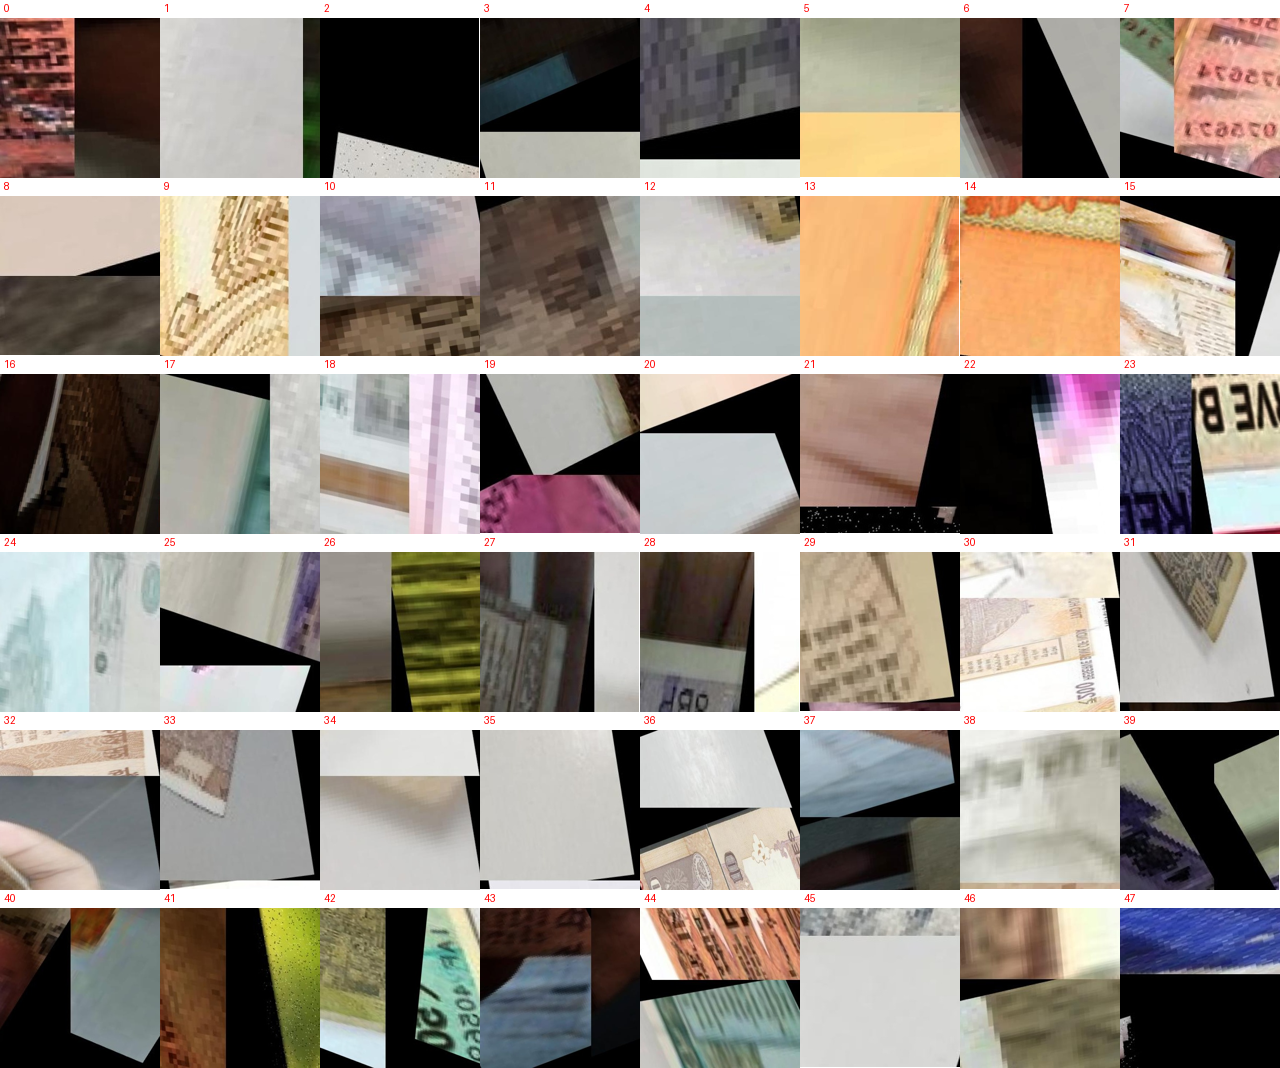

In [24]:
import glob
from IPython.display import display, Image as IPImage
sheets = sorted(glob.glob('/content/work/contact_sheets/sheet_*.png'))
print(len(sheets), 'sheets')
SHEET = 0
print(sheets[SHEET])
display(IPImage(sheets[SHEET], width=1280))

Look up which file a number is (optional):

In [25]:
import csv
rows = dict((int(i), n) for i, n in csv.reader(open('/content/work/contact_sheets/index.csv')))
for i in [0]:   # numbers to look up
    print(i, rows[i])

0 rfcrop-train__010_jpg.rf.053baa4a1776a84dd3603648675d63da.jpg


Reject numbers from the sheets. **Do not rerun `prepare` between viewing a sheet and rejecting** — numbers come from the latest `prepare`.
Rejections are saved on Drive and re-applied automatically on later `prepare` runs.

In [26]:
REJECT = []   # e.g. [3, 17, 40]
if REJECT:
    import subprocess
    subprocess.run(['python', 'train_currency.py', 'reject', *map(str, REJECT)], cwd='/content', check=True)
else:
    print('nothing to reject yet')

nothing to reject yet


## 6. Train, evaluate, export
Takes ~10–20 min on a T4. Log goes to `/content/work/train.log`.

In [27]:
!cd /content && python train_currency.py train 2>&1 | tee /content/work/train.log

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
INDIAN = /content/work/raw/Thai and Indian Currency Dataset256x256/Thai and Indian Currency Dataset256x256/Indian Currencies
      '10 New' ->   10: 250 images
      '10 Old' ->   10: 190 images
     '100 New' ->  100: 190 images
     '100 Old' ->  100: 190 images
          '20' ->   20: 190 images
         '200' ->  200: 190 images
  skipping folder "2000"
      '50 New' ->   50: 190 images
      '50 Old' ->   50: 190 images
         '500' ->  500: 190 images
        10: 440 unique from 440 sources (0 exact duplicates dropped)
        20: 190 unique from 190 sources (0 exact duplicates dropped)
        50: 380 unique from 380 sources (0 exact duplicates dropped)
       100: 380 unique from 380 sources (0 exact duplicates dropped)
       200: 190 unique from 190 sources (0 exact duplicates dropped)
       500: 190 unique from 190 sources (0 exact duplicates dropped)
background: 374 unique from 151 sourc

## 7. Results

In [28]:
import json
r = json.load(open('/content/drive/MyDrive/currency/results.json'))
print('train counts :', r['train_counts'])
print('float32 acc  :', r['test_accuracy_keras_float32'])
print('INT8 acc     :', r['test_accuracy_litert_int8'])
print('bg spoken as note @0.85:', r['background_spoken_as_note_at_0.85'])
print('tflite MB    :', r['tflite_mb'])
for t, v in r['thresholds'].items():
    print(f"threshold {float(t):.2f}: speaks {v['speaks_on_notes']:.1%}, wrong {v['wrong_when_speaking']:.1%}")
low = {k: v for k, v in r['train_counts'].items() if v < 150}
if low: print('!! LOW CLASSES (<150):', low)

train counts : {'10': 374, '100': 323, '20': 162, '200': 162, '50': 323, '500': 162, 'background': 315}
float32 acc  : 0.8576
INT8 acc     : 0.709
bg spoken as note @0.85: 0.0
tflite MB    : 1.24
threshold 0.50: speaks 75.4%, wrong 6.5%
threshold 0.60: speaks 62.9%, wrong 2.4%
threshold 0.70: speaks 49.6%, wrong 0.0%
threshold 0.80: speaks 33.7%, wrong 0.0%
threshold 0.85: speaks 26.1%, wrong 0.0%
threshold 0.90: speaks 17.8%, wrong 0.0%
threshold 0.95: speaks 6.8%, wrong 0.0%


In [ ]:
from IPython.display import display, Image as IPImage
for f in ['cm_test.png', 'curves.png', 'augmented_samples.png']:
    print(f); display(IPImage('/content/drive/MyDrive/currency/' + f))

## 8. Download for Android
Copy `currency_model.tflite` and `labels.txt` into `app/src/main/assets/`. Files also live in `MyDrive/currency/`.

**Check:** INT8 accuracy within ~2 points of float32; `background_spoken_as_note_at_0.85` ≈ 0%; pick the lowest threshold where `wrong_when_speaking` ≈ 0% for `Stabilizer(threshold = …)`.

In [ ]:
from google.colab import files
files.download('/content/drive/MyDrive/currency/currency_model.tflite')
files.download('/content/drive/MyDrive/currency/labels.txt')

In [21]:
# DIAGNOSTIC: does the saved .tflite load, and which interpreter option works?
import os, tensorflow as tf
print(os.popen('grep -n "BUILTIN_WITHOUT_DEFAULT_DELEGATES" /content/train_currency.py').read() or 'FIX NOT IN SCRIPT')
p = '/content/drive/MyDrive/currency/currency_model.tflite'
print('size bytes:', os.path.getsize(p))
R = tf.lite.experimental.OpResolverType
for name, kw in [('no default delegates', dict(experimental_op_resolver_type=R.BUILTIN_WITHOUT_DEFAULT_DELEGATES)),
                 ('reference kernels',    dict(experimental_op_resolver_type=R.BUILTIN_REF)),
                 ('default',              {})]:
    try:
        i = tf.lite.Interpreter(model_path=p, **kw); i.allocate_tensors()
        d = i.get_input_details()[0]
        print(name, '-> OK', d['shape'], d['dtype'])
    except Exception as e:
        print(name, '-> FAIL', str(e)[:150])


FIX NOT IN SCRIPT
size bytes: 1241352
no default delegates -> OK [  1 224 224   3] <class 'numpy.float32'>
reference kernels -> OK [  1 224 224   3] <class 'numpy.float32'>
default -> FAIL failed to create XNNPACK runtimeNode number 119 (TfLiteXNNPackDelegate) failed to prepare.


In [29]:
# Compare export formats on the test split (no retraining). Run once, paste the output.
import os, numpy as np, tensorflow as tf
OUT, DATA = '/content/drive/MyDrive/currency', '/content/work/dataset'

print(os.popen('grep -B2 -A12 "precision" /content/work/train.log').read())

model = tf.keras.models.load_model(f'{OUT}/best.keras')
test = tf.keras.utils.image_dataset_from_directory(
    f'{DATA}/test', image_size=(224, 224), batch_size=1, label_mode='categorical',
    crop_to_aspect_ratio=True, shuffle=False)
X = [(x.numpy().astype(np.float32), int(np.argmax(y))) for x, y in test]
print(len(X), 'test images')

R = tf.lite.experimental.OpResolverType
def evaluate(tfl):
    it = tf.lite.Interpreter(model_content=tfl,
                             experimental_op_resolver_type=R.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
    it.allocate_tensors()
    i, o = it.get_input_details()[0], it.get_output_details()[0]
    ok = 0
    for x, y in X:
        it.set_tensor(i['index'], x); it.invoke()
        ok += int(np.argmax(it.get_tensor(o['index'])) == y)
    return ok / len(X), i['dtype'].__name__, o['dtype'].__name__

keras_acc = np.mean([int(np.argmax(model.predict(x, verbose=0)) == y) for x, y in X])
print('keras float32 accuracy:', round(float(keras_acc), 4))

model.export('/content/work/saved_model2')
def convert(configure):
    c = tf.lite.TFLiteConverter.from_saved_model('/content/work/saved_model2')
    configure(c)
    return c.convert()

variants = {
    'float32':       lambda c: None,
    'dynamic_range': lambda c: setattr(c, 'optimizations', [tf.lite.Optimize.DEFAULT]),
    'float16':       lambda c: (setattr(c, 'optimizations', [tf.lite.Optimize.DEFAULT]),
                                setattr(c.target_spec, 'supported_types', [tf.float16])),
}
for name, cfg in variants.items():
    tfl = convert(cfg)
    open(f'{OUT}/currency_model_{name}.tflite', 'wb').write(tfl)
    acc, idt, odt = evaluate(tfl)
    print(f'{name:14s} {len(tfl)/1e6:5.2f} MB  test acc {acc:.4f}  input {idt} output {odt}')



 1/49 ━━━━━━━━━━━━━━━━━━━━ 58s 1s/step - accuracy: 0.9062 - loss: 0.68
 2/49 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - accuracy: 0.9062 - loss: 0.696
 3/49 ━━━━━━━━━━━━━━━━━━━━ 38s 831ms/step - accuracy: 0.8993 - loss: 0.731
 4/49 ━━━━━━━━━━━━━━━━━━━━ 28s 631ms/step - accuracy: 0.8913 - loss: 0.757
 5/49 ━━━━━━━━━━━━━━━━━━━━ 38s 864ms/step - accuracy: 0.8830 - loss: 0.774
 6/49 ━━━━━━━━━━━━━━━━━━━━ 33s 772ms/step - accuracy: 0.8765 - loss: 0.784
 7/49 ━━━━━━━━━━━━━━━━━━━━ 34s 822ms/step - accuracy: 0.8712 - loss: 0.790
 8/49 ━━━━━━━━━━━━━━━━━━━━ 30s 747ms/step - accuracy: 0.8663 - loss: 0.794
 9/49 ━━━━━━━━━━━━━━━━━━━━ 29s 748ms/step - accuracy: 0.8622 - loss: 0.799
10/49 ━━━━━━━━━━━━━━━━━━━━ 26s 692ms/step - accuracy: 0.8582 - loss: 0.804
11/49 ━━━━━━━━━━━━━━━━━━━━ 26s 705ms/step - accuracy: 0.8548 - loss: 0.808
12/49 ━━━━━━━━━━━━━━━━━━━━ 24s 654ms/step - accuracy: 0.8528 - loss: 0.811
13/49 ━━━━━━━━━━━━━━━━━━━━ 24s 669ms/step - accuracy: 0.8508 - loss: 0.814
14/49 ━━━━━━━━━━━━━━━━━━━━ 22s

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


float32         3.77 MB  test acc 0.8576  input float32 output float32
dynamic_range   1.13 MB  test acc 0.8638  input float32 output float32
float16         1.95 MB  test acc 0.8514  input float32 output float32


In [30]:
# Finalise: use the dynamic-range model, print per-class report, download for Android
import shutil, os
from google.colab import files
OUT = '/content/drive/MyDrive/currency'
shutil.copy(f'{OUT}/currency_model_dynamic_range.tflite', f'{OUT}/currency_model.tflite')
print(open(f'{OUT}/labels.txt').read().split('\n'), '<- label order for the app')
print('currency_model.tflite MB:', round(os.path.getsize(f'{OUT}/currency_model.tflite') / 1e6, 2))
# per-class report from the training log (skips the TensorSpec noise)
lines = open('/content/work/train.log', errors='ignore').read().splitlines()
for k, l in enumerate(lines):
    if 'precision' in l and 'recall' in l:
        print('\n'.join(lines[k:k + 14])); break
files.download(f'{OUT}/currency_model.tflite')
files.download(f'{OUT}/labels.txt')


['10', '100', '20', '200', '50', '500', 'background'] <- label order for the app
currency_model.tflite MB: 1.13
              precision    recall  f1-score   support

          10      0.857     0.909     0.882        66
         100      0.895     0.596     0.716        57
          20      0.964     0.964     0.964        28
         200      1.000     0.929     0.963        28
          50      0.637     0.895     0.745        57
         500      0.929     0.929     0.929        28
  background      1.000     0.898     0.946        59

    accuracy                          0.858       323
   macro avg      0.897     0.874     0.878       323
weighted avg      0.879     0.858     0.858       323



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>